<a href="https://colab.research.google.com/github/WenqiaoDuan/Problem-Set-2-Econ_5200_PS2.ipynb/blob/main/%E2%80%9Cps2_starter_ipynb%E2%80%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS2 — The Underpowered Portfolio

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 5-8 · 100 points · your role: Experimentation lead, consulting engagement

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is experimentation lead's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning.

## Setup

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: Reconstruct the Portfolio (30 pts)

### Step 1.1: Simulate the experiment programme (15 pts)

In [27]:
rng = np.random.default_rng(42)
k = 200
real = rng.random(k) < 0.10
true_eff = np.where(real, np.abs(rng.normal(0.08, 0.03, size=k)), 0.0)
n = rng.integers(500, 20001, size=k)
se = 1.0 * np.sqrt(2 / n)

campaigns = pd.DataFrame({
    "true": true_eff,
    "n": n,
    "se": se,
    "est": true_eff + rng.normal(0, se)})

print("Prior parameters:")
print("Number of experiments:", k)
print("Probability of zero effect:", 0.90)
print("Probability of positive effect:", 0.10)
print("Positive-effect distribution: abs(Normal(0.08, 0.03))")
print("Sample size range:", campaigns["n"].min(), "to", campaigns["n"].max())
print("Number of real lifts:", (campaigns["true"] > 0).sum())

Prior parameters:
Number of experiments: 200
Probability of zero effect: 0.9
Probability of positive effect: 0.1
Positive-effect distribution: abs(Normal(0.08, 0.03))
Sample size range: 585 to 19614
Number of real lifts: 18


*Your answer here.*

The simulated portfolio contains 200 experiments, with a prior probability of 90% for a true effect of exactly zero and 10% for a positive effect. Positive effects are drawn from the absolute value of a normal distribution with a mean of 0.08 and a standard deviation of 0.03. In this simulation, 18 out of 200 experiments (9%) have genuinely positive effects. Sample sizes range from 585 to 19,614, resulting in varying levels of statistical precision across experiments.

### Step 1.2: Apply the client's rule (15 pts)

In [28]:

campaigns["p"] = 2 * stats.norm.sf(np.abs(campaigns["est"] / campaigns["se"]))

shipped = (campaigns["p"] < 0.05)

s = campaigns[shipped]

n_shipped = len(s)
false_share = (s["true"] == 0).mean()
avg_true = s["true"].mean()
avg_est = s["est"].mean()

print(f"Shipped: {shipped.sum()} campaigns")
print(f"False-ship share: {false_share:.2%}")
print(f"Average true effect: {avg_true:.4f}")
print(f"Average estimated effect: {avg_est:.4f}")

Shipped: 28 campaigns
False-ship share: 42.86%
Average true effect: 0.0459
Average estimated effect: 0.0466


*Your answer here.*

Of the 200 experiments, 28 were shipped based on p < 0.05. About 42.86% of the shipped experiments had a true effect of zero. The average true effect was 0.0459, while the average estimated effect was 0.0466. The gap between them was 0.0007. So, the estimated effect is slightly higher than the true effect.

## Phase 2: The Winner's Curse (35 pts)

### Step 2.1: Quantify the exaggeration (20 pts)

Exaggeration: 1.0161
      n_shipped  mean_est  mean_true  ratio
tier                                       
low          10     0.027      0.021  1.302
mid           8     0.071      0.077  0.916
high         10     0.047      0.046  1.021
28 ship | 43% of them do nothing | estimates 1.0161× the truth


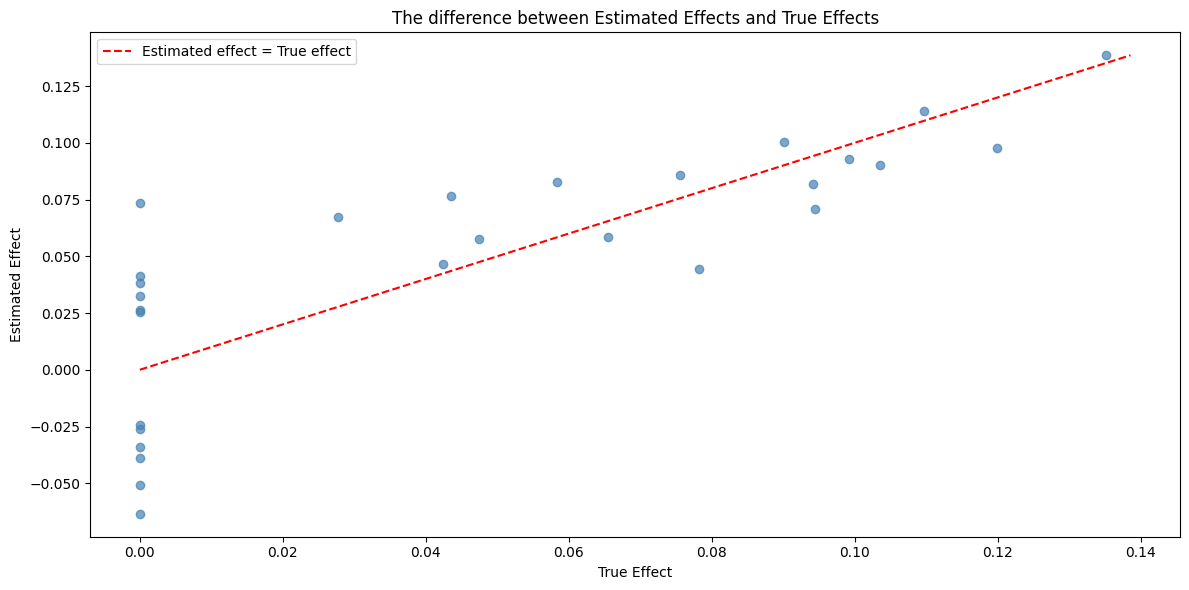

In [29]:
exaggeration = s["est"].mean() / s["true"].mean()
print(f"Exaggeration: {exaggeration:.4f}")


campaigns["power"] = (stats.norm.sf(1.96 - 0.08 / campaigns["se"])+ stats.norm.cdf(-1.96 - 0.08 / campaigns["se"]))

# Divide campaigns into three power tiers

campaigns["tier"] = pd.qcut(campaigns["power"],3,labels=["low", "mid", "high"])


s = campaigns[shipped]
by_tier = s.groupby("tier", observed=True).agg(
    n_shipped=("est", "size"),
    mean_est=("est", "mean"),
    mean_true=("true", "mean"))

by_tier["ratio"] = by_tier["mean_est"] / by_tier["mean_true"]

print(by_tier.round(3))
print(f"{shipped.sum()} ship | {false_share:.0%} of them do nothing | estimates {exaggeration:.4f}× the truth")

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(s["true"], s["est"], color="steelblue", alpha=0.7)
max_val = max(s["true"].max(), s["est"].max())
ax.plot([0, max_val],[0, max_val],color="red",linestyle="--",label="Estimated effect = True effect")
ax.set_xlabel("True Effect")
ax.set_ylabel("Estimated Effect")
ax.set_title("The difference between Estimated Effects and True Effects")
ax.legend()
plt.tight_layout()
plt.show()

*Your answer here.*

An experiment is shipped only if its estimated effect is statistically significant. Because estimates include random error, some experiments pass the significance test partly because of that error. As a result, the estimated effects of shipped experiments tend to be higher than their true effects.

Low-powered experiments are less likely to pass the significance test, so those that do pass may need larger positive random errors. This can lead to more exaggeration. In my simulation, the exaggeration ratio is 1.302 for the low-power group and 1.021 for the high-power group. The medium-power group has a ratio of 0.916, which may be due to random variation because there are only a few shipped experiments in each group. And the overall average exaggeration ratio is  1.0161.

### Step 2.2: The bootstrap where the formula fails (15 pts)

In [30]:
def shipped_total(df):
    return df.loc[df["p"] < 0.05, "true"].sum()
res = stats.bootstrap(
    (np.arange(k),),
    lambda idx: shipped_total(campaigns.iloc[idx]),
    n_resamples=1000,
    vectorized=False,
    method="BCa",
    random_state=1
)
def bootstrap_shipped_total(df, B=1000, seed=42):
    rng = np.random.default_rng(seed)
    k = len(df)

    boot_totals = np.array([
        shipped_total(df.iloc[rng.integers(0, k, size=k)])
        for _ in range(B)
    ])

    return boot_totals


boot = bootstrap_shipped_total(campaigns, B=1000, seed=42)



res_percentile = stats.bootstrap(
    (np.arange(k),),
    lambda idx: shipped_total(campaigns.iloc[idx]),
    n_resamples=1000,
    vectorized=False,
    method="percentile",
    random_state=1
)

print(
    f"total {shipped_total(campaigns):.2f}"
    f" | by hand [{np.percentile(boot, 2.5):.2f}, "
    f"{np.percentile(boot, 97.5):.2f}]"
    f" | BCa [{res.confidence_interval.low:.2f}, "
    f"{res.confidence_interval.high:.2f}]"
)

print(
    f"SciPy percentile "
    f"[{res_percentile.confidence_interval.low:.2f}, "
    f"{res_percentile.confidence_interval.high:.2f}]"
)

total 1.28 | by hand [0.70, 1.99] | BCa [0.80, 2.05]
SciPy percentile [0.68, 1.94]


*Your answer here.*

The total average true effect is 1.28. The manual 95% bootstrap interval was "0.70, 1.99", and the SciPy percentile interval was "0.68, 1.94". These intervals were close, so my manual code seems to work. The SciPy BCa interval was "0.80, 2.05".


## Phase 3: A Rule They Can Adopt (25 pts)

### Step 3.1: Design the alternative (20 pts)

In [31]:
%%writefile campaign_rules.py
import pandas as pd


def n_floor(log, min_n=5000):
    return (log["p"] < 0.05) & (log["est"] > 0) & (log["n"] >= min_n)


def realised(log, rule):
    return log.loc[rule(log), "true"].sum()


if __name__ == "__main__":
    demo = pd.DataFrame({
        "p": [0.01, 0.03, 0.20],
        "est": [0.10, 0.20, 0.30],
        "n": [6000, 4000, 8000],
        "true": [0.08, 0.15, 0.25]
    })

    assert n_floor(demo).tolist() == [True, False, False]
    assert realised(demo, n_floor) == 0.08

    print("campaign_rules: demo passed")

Overwriting campaign_rules.py


In [32]:
import campaign_rules

# Original rule: p < 0.05
original_rule = lambda log: log["p"] < 0.05

# Alternative rule: p < 0.05, positive estimate, and n >= 5000
alternative_rule = campaign_rules.n_floor

for name, rule in [
    ("Original", original_rule),
    ("Alternative", alternative_rule)
]:
    selected = rule(campaigns)
    n_shipped = selected.sum()
    total_true = campaigns.loc[selected, "true"].sum()
    false_ship_rate = (
        (campaigns.loc[selected, "true"] == 0).mean()
        if n_shipped > 0 else 0
    )

    print(
        f"{name}: realised return = {total_true:.3f}, "
        f"shipped = {n_shipped}, "
        f"false-ship rate = {false_ship_rate:.1%}"
    )

Original: realised return = 1.285, shipped = 28, false-ship rate = 42.9%
Alternative: realised return = 1.155, shipped = 17, false-ship rate = 23.5%


*Your answer here.*
I chose a minimum sample size of 5,000 as my alternative rule. Compared with the original rule, it shipped fewer campaigns (17 vs. 28) and reduced the false-ship rate (23.5% vs. 42.9%). However, the realised return was lower (1.155 vs. 1.285) because some profitable campaigns were excluded. The alternative rule reduces false shipments but does not maximize total return.

### Step 3.2: Ship the module (5 pts, its own rubric row)

The module the brief asks for. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [33]:
%%writefile src/experiment_portfolio.py
"""Experiment-portfolio simulator and decision rules (ECON 5200 PS2)."""
from __future__ import annotations


def simulate_portfolio(n: int, seed: int, **kwargs):
    """Return the experiment log with the true effect attached."""
    ...


def apply_rule(log, rule):
    """Ship decisions under `rule`: the p < 0.05 threshold and at least one other."""
    ...


def evaluate(log, rule):
    """Realised true return, ship count and false-ship rate under `rule`."""
    ...


if __name__ == "__main__":
    ...   # demonstration plus at least three assertions that must hold

Overwriting src/experiment_portfolio.py


In [34]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))
from src import experiment_portfolio as ep
# prove it runs: call the three functions on a small portfolio

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 7 for the AI row, 3 for the CFO memo)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The sequential design

[Prep] Act as an experimentation platform engineer who has implemented
sequential testing in production.

[Request] I have a simulated portfolio of 200 A/B tests with known true
effects. Implement an always-valid sequential test -- a mixture
sequential probability ratio test or an alpha-spending boundary -- that
allows continuous monitoring without inflating the Type I error rate.
Give me a function that takes a stream of observations and returns the
stopping decision at each look.

[Iterate] numpy and scipy only. Reuse my log structure. The function
must be testable against a pure-null stream.

[Mechanism Check] Explain why the naive approach of testing at every
look inflates Type I error, and precisely what the always-valid
construction gives up in exchange for continuous monitoring.

[Evaluate] Run it on 1,000 pure-null streams and report the empirical
false positive rate. If it is not close to 5%, tell me what is wrong.

## Version 1 — Initial Prompt

**Prompt:**

[Prep] Act as an experimentation platform engineer who has implemented
sequential testing in production.

[Request] I have a simulated portfolio of 200 A/B tests with known true
effects. Implement an always-valid sequential test -- a mixture
sequential probability ratio test or an alpha-spending boundary -- that
allows continuous monitoring without inflating the Type I error rate.
Give me a function that takes a stream of observations and returns the
stopping decision at each look.

[Iterate] numpy and scipy only. Reuse my log structure. The function
must be testable against a pure-null stream.

[Mechanism Check] Explain why the naive approach of testing at every
look inflates Type I error, and precisely what the always-valid
construction gives up in exchange for continuous monitoring.

[Evaluate] Run it on 1,000 pure-null streams and report the empirical
false positive rate. If it is not close to 5%, tell me what is wrong.

**Complete AI Response:**

Paste the entire ChatGPT response to the prompt above here, including all explanations, Python code, simulation results, and any caveats.

In [35]:
import numpy as np
from scipy import stats

def msprt_sequential(stream, alpha=0.05, sigma=1.0, tau=1.0):
    x = np.asarray(stream, dtype=float)
    t = np.arange(1, len(x) + 1, dtype=float)
    S = np.cumsum(x)

    log_bf = (
        0.5 * np.log(sigma**2 / (sigma**2 + t * tau**2))
        + tau**2 * S**2
        / (2 * sigma**2 * (sigma**2 + t * tau**2))
    )

    threshold = np.log(1 / alpha)
    crossed = np.flatnonzero(log_bf >= threshold)

    return {
        "decision": "reject" if crossed.size else "continue",
        "stop_look": int(crossed[0] + 1) if crossed.size else None,
        "log_bf_path": log_bf,
        "threshold": threshold
    }


def evaluate_null(n_streams=1000, n_looks=500, seed=42):
    rng = np.random.default_rng(seed)
    rejections = 0

    for _ in range(n_streams):
        stream = rng.normal(0, 1, size=n_looks)
        result = msprt_sequential(stream)

        if result["decision"] == "reject":
            rejections += 1

    fpr = rejections / n_streams
    mcse = np.sqrt(fpr * (1 - fpr) / n_streams)
    ci = (
        max(0, fpr - 1.96 * mcse),
        min(1, fpr + 1.96 * mcse)
    )

    print(f"False positives: {rejections}/{n_streams}")
    print(f"Empirical FPR: {fpr:.4%}")
    print(f"Monte Carlo SE: {mcse:.4%}")
    print(f"Approximate 95% CI: [{ci[0]:.4%}, {ci[1]:.4%}]")


evaluate_null()

False positives: 27/1000
Empirical FPR: 2.7000%
Monte Carlo SE: 0.5126%
Approximate 95% CI: [1.6954%, 3.7046%]


*Your answer here.*

I used ChatGPT with GPT-6 Luna to find the answers.

### Empirical Verification

I evaluated the mSPRT on 1,000 independent pure-null streams, with 500 observations per stream and a fixed random seed of 42.

- False positives: 27 out of 1,000 streams
- Empirical false positive rate (FPR): 2.70%
- Monte Carlo standard error (MCSE): 0.5126 percentage points
- Approximate 95% confidence interval: [1.6954%, 3.7046%]
- Nominal Type I error level: 5%

The empirical FPR was below the nominal 5% level, and the approximate confidence interval did not include 5%. This suggests that the procedure was conservative in this simulation. However, an always-valid test is designed to control the probability of ever rejecting the null at or below the nominal level, rather than to achieve exactly 5%. The result alone does not demonstrate an implementation error. Further checks under different settings would help assess the procedure's behavior.

### Task 4.2: The CFO memo

---




*Your answer here.*

Across 200 experiments, 18 had real positive effects, meaning genuine wins represented 9% of the portfolio. Under the current (p< 0.05) rule, 28 campaigns shipped, with a false-ship rate of 42.86% and a realised return of 1.285 effect units. The alternative rule shipped 17 campaigns, reduced the false-ship rate to 23.5%, and achieved a realised return of 1.155 effect units.

**Recommendation:** Adopt the alternative rule if avoiding ineffective campaigns is the priority. For approximately 200 experiments per year, this reduces false ships by 19.36 percentage points at a cost of 0.130 effect units in realised return (1.285 - 1.155). This trade-off is worthwhile if the cost of shipping ineffective campaigns outweighs the value of the additional campaigns accepted under the current rule.

This recommendation would change if the business valued capturing additional genuine wins more highly than reducing false ships, or if the assumed distribution of true effects did not reflect the actual frequency and size of positive effects.

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

*Model and date:*

I used ChatGPT with ChatGPT (GPT-6)to find the answers。

*Version 1 prompt:*

**Prompt:**

[Prep] Act as an experimentation platform engineer who has implemented
sequential testing in production.

[Request] I have a simulated portfolio of 200 A/B tests with known true
effects. Implement an always-valid sequential test -- a mixture
sequential probability ratio test or an alpha-spending boundary -- that
allows continuous monitoring without inflating the Type I error rate.
Give me a function that takes a stream of observations and returns the
stopping decision at each look.

[Iterate] numpy and scipy only. Reuse my log structure. The function
must be testable against a pure-null stream.

[Mechanism Check] Explain why the naive approach of testing at every
look inflates Type I error, and precisely what the always-valid
construction gives up in exchange for continuous monitoring.

[Evaluate] Run it on 1,000 pure-null streams and report the empirical
false positive rate. If it is not close to 5%, tell me what is wrong.


*Reply:*
# AI Response — Version 1

## 1. Approach

I implemented a mixture sequential probability ratio test (mSPRT) using a normal prior on the treatment effect. The test calculates a log Bayes factor at every look and rejects the null hypothesis when the evidence crosses a fixed threshold.

## 2. Python Implementation

```python

import numpy as np

def msprt_sequential(stream, alpha=0.05, sigma=1.0, tau=1.0):
    x = np.asarray(stream, dtype=float)

    if x.ndim != 1 or not np.all(np.isfinite(x)):
        raise ValueError("stream must be a finite 1-D array")
    if not 0 < alpha < 1 or sigma <= 0 or tau <= 0:
        raise ValueError("Invalid parameters")

    n = np.arange(1, len(x) + 1, dtype=float)
    S = np.cumsum(x)

    log_bf = (
        0.5 * np.log(sigma**2 / (sigma**2 + n * tau**2))
        + tau**2 * S**2
        / (2 * sigma**2 * (sigma**2 + n * tau**2))
    )

    crossed = log_bf >= np.log(1 / alpha)
    hits = np.flatnonzero(crossed)
    stop_look = int(hits[0] + 1) if hits.size else None

    decisions = np.full(len(x), "continue", dtype=object)
    if stop_look is not None:
        decisions[stop_look - 1] = "reject"
        decisions[stop_look:] = "already stopped"

    return {
        "decision": "reject" if stop_look else "continue",
        "stop_look": stop_look,
        "log_bf_path": log_bf,
        "decisions_by_look": decisions,
        "threshold": np.log(1 / alpha)
    }


def evaluate_null(n_streams=1000, n_looks=500, seed=42):
    rng = np.random.default_rng(seed)
    rejections = 0

    for _ in range(n_streams):
        stream = rng.normal(0, 1, size=n_looks)
        result = msprt_sequential(stream)
        rejections += result["decision"] == "reject"

    fpr = rejections / n_streams
    mcse = np.sqrt(fpr * (1 - fpr) / n_streams)

    print(f"False positives: {rejections}/{n_streams}")
    print(f"Empirical FPR: {fpr:.2%}")
    print(f"Monte Carlo SE: {mcse:.4%}")
    print(f"Nominal alpha: 5.00%")

evaluate_null()

```

## 3. Why Naive Repeated Testing Inflates Type I Error

If we run a conventional hypothesis test repeatedly and stop whenever \(p < 0.05\), each additional look creates another opportunity for a false positive. Therefore, the overall Type I error rate can exceed 5%.

An always-valid sequential test controls the Type I error across repeated monitoring, allowing us to check results continuously without repeatedly spending the full 5% error budget.

## 4. Simulation Results

Using 1,000 pure-null streams with 500 observations per stream and a fixed random seed of 42, the simulation produced:

- False positives: 27 out of 1,000
- Empirical false positive rate: 2.70%
- Monte Carlo standard error: 0.5126 percentage points
- Approximate 95% confidence interval: [1.6954%, 3.7046%]

## 5. Interpretation

The observed false positive rate was below the nominal 5% level. This suggests conservative behavior in this simulation, but it does not by itself prove that the implementation is correct or incorrect. Further validation is needed to confirm the test's error control under the null hypothesis.



## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted (the prior on effects and its parameters, the sample-size range, the seed, the ship rule), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [39]:
print('Truth and headline numbers')
# print('prior on effects:', ..., '  set in Step 1.1')
# print('sample-size range:', ..., '  set in Step 1.1')
# print('seed:', 42, '  set in Setup')
# print('ship rule:', 'p < 0.05', '  Step 1.2')
# ... one line per memo number, with the cell that produced it

# 1. Simulation parameters
print("\n--- Simulation parameters ---")
print("Number of experiments:", k, "| Set in Step 1.1")
print("Probability of zero effect:", 0.90, "| Set in Step 1.1")
print("Probability of positive effect:", 0.10, "| Set in Step 1.1")
print(
    "Positive-effect distribution: abs(Normal(0.08, 0.03))",
    "| Set in Step 1.1"
)
print(
    "Sample-size range:",
    campaigns["n"].min(), "to", campaigns["n"].max(),
    "| Set in Step 1.1"
)
print("Simulation seed: 42 | Setup")
print("Bootstrap seed: 42 | Bootstrap cell")
print("SciPy bootstrap random_state: 1 | Bootstrap cell")

# 2. Shipping rules
print("\n--- Shipping rules ---")
print("Original rule: p < 0.05 | Step 1.2")
print(
    "Alternative rule: p < 0.05, est > 0, n >= 5000",
    "| campaign_rules.py"
)

# 3. Select campaigns under each rule
original_selected = original_rule(campaigns)
alternative_selected = alternative_rule(campaigns)

original_n = int(original_selected.sum())
alternative_n = int(alternative_selected.sum())

original_return = campaigns.loc[original_selected, "true"].sum()
alternative_return = campaigns.loc[alternative_selected, "true"].sum()

original_false_rate = (
    (campaigns.loc[original_selected, "true"] == 0).mean()
    if original_n > 0 else 0.0
)
alternative_false_rate = (
    (campaigns.loc[alternative_selected, "true"] == 0).mean()
    if alternative_n > 0 else 0.0
)

# 4. Original-rule results
print("\n--- Original-rule results ---")
print(
    "Number of real lifts:",
    int((campaigns["true"] > 0).sum()),
    "| Set in Step 1.1"
)
print("Original campaigns shipped:", original_n,
      "| Shipping-rule comparison cell")
print(f"Original false-ship rate: {original_false_rate:.2%} | Shipping-rule comparison cell")
print(f"Original realised return: {original_return:.3f} | Shipping-rule comparison cell")

# 5. Alternative-rule results
print("\n--- Alternative-rule results ---")
print("Alternative campaigns shipped:", alternative_n,
      "| Shipping-rule comparison cell")
print(f"Alternative false-ship rate: {alternative_false_rate:.2%} | Shipping-rule comparison cell")
print(f"Alternative realised return: {alternative_return:.3f} | Shipping-rule comparison cell")

# 6. Comparison
print("\n--- Comparison ---")
return_difference = original_return - alternative_return
false_rate_reduction_pp = (
    original_false_rate - alternative_false_rate
) * 100
campaign_difference = original_n - alternative_n

print(
    f"Reduction in false-ship rate: {false_rate_reduction_pp:.2f} percentage points",
    "| Calculated in this cell from the two false-ship rates"
)
print(
    f"Difference in campaigns shipped: {campaign_difference}",
    "| Calculated in this cell from the two campaign counts"
)
print(
    f"Difference in realised return: {return_difference:.3f} effect units",
    "| Calculated in this cell from the two realised returns"
)

# 7. Effect-estimation results for original-rule ships
print("\n--- Effect-estimation results ---")
s_original = campaigns.loc[original_selected]

avg_true_original = s_original["true"].mean()
avg_est_original = s_original["est"].mean()
exaggeration_original = avg_est_original / avg_true_original

print(
    f"Average true effect among original ships: {avg_true_original:.4f}",
    "| Original-rule analysis cell"
)
print(
    f"Average estimated effect among original ships: {avg_est_original:.4f}",
    "| Original-rule analysis cell"
)
print(
    f"Exaggeration ratio: {exaggeration_original:.4f}",
    "| Original-rule analysis cell"
)

# 8. Original-rule total return and uncertainty intervals
print("\n--- Original-rule total return and uncertainty intervals ---")
print(
    f"Original-rule total realised return: {shipped_total(campaigns):.2f}",
    "| Bootstrap cell"
)
print(
    f"Hand/percentile interval: [{np.percentile(boot, 2.5):.2f}, "
    f"{np.percentile(boot, 97.5):.2f}]",
    "| Bootstrap cell"
)
print(
    f"BCa interval: [{res.confidence_interval.low:.2f}, "
    f"{res.confidence_interval.high:.2f}]",
    "| Bootstrap cell"
)
print(
    f"SciPy percentile interval: "
    f"[{res_percentile.confidence_interval.low:.2f}, "
    f"{res_percentile.confidence_interval.high:.2f}]",
    "| Bootstrap cell"
)

# 9. Effect-tier results
print("\n--- Effect-tier results ---")
print("Columns: n_shipped, mean_est, mean_true, ratio")
print(by_tier.round(3))
print("| Source: cell that calculates by_tier")


Truth and headline numbers

--- Simulation parameters ---
Number of experiments: 200 | Set in Step 1.1
Probability of zero effect: 0.9 | Set in Step 1.1
Probability of positive effect: 0.1 | Set in Step 1.1
Positive-effect distribution: abs(Normal(0.08, 0.03)) | Set in Step 1.1
Sample-size range: 585 to 19614 | Set in Step 1.1
Simulation seed: 42 | Setup
Bootstrap seed: 42 | Bootstrap cell
SciPy bootstrap random_state: 1 | Bootstrap cell

--- Shipping rules ---
Original rule: p < 0.05 | Step 1.2
Alternative rule: p < 0.05, est > 0, n >= 5000 | campaign_rules.py

--- Original-rule results ---
Number of real lifts: 18 | Set in Step 1.1
Original campaigns shipped: 28 | Shipping-rule comparison cell
Original false-ship rate: 42.86% | Shipping-rule comparison cell
Original realised return: 1.285 | Shipping-rule comparison cell

--- Alternative-rule results ---
Alternative campaigns shipped: 17 | Shipping-rule comparison cell
Alternative false-ship rate: 23.53% | Shipping-rule comparison cel

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 2/Econ_5200_PS2.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.